# 07. Notebook 04 model, using the pipeline

The same steps as `04_eda_and_multivariate copy.ipynb`, but every step is a call to
`modeling/kaub_pipeline.py`:

1. load the daily data
2. create features and the 7-day-ahead target
3. split by time
4. train XGBoost and evaluate it
5. save the model, load it again and use it to forecast

The pipeline can also run on its own: `uv run python -m modeling.kaub_pipeline`

In [1]:
# importing libraries
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

In [2]:
# importing the pipelines
from modeling import kaub_pipeline as kp
from modeling import hydro_pipeline as hp

H = kp.HORIZON
LOW_WATER_THRESHOLD = hp.LOW_WATER_CM

print("Forecast horizon:", H, "days")
print("Low-water threshold:", LOW_WATER_THRESHOLD, "cm")

Forecast horizon: 7 days
Low-water threshold: 78 cm


## Step 1: Load the data

In [3]:
# Load the daily Kaub + weather data
daily = kp.load_data()

print(daily.shape)
daily.head()

(9741, 19)


,water_level_mean,water_level_min,water_level_max,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,et0_sum,hours_available,hours_expected
date,,,,,,,,,,,,,,,,,,,
2000-01-01,438.989130,420.0,459.0,359.304348,345.0,374.0,3274.347826,3120.0,3440.0,3.430435,97.565217,1.7,1.7,0.0,1025.382609,7.769565,0.14,23,24
2000-01-02,401.260417,384.0,420.0,333.125000,321.0,345.0,2970.312500,2830.0,3120.0,3.866667,96.208333,0.0,0.0,0.0,1030.579167,6.225000,0.23,24,24
2000-01-03,367.989583,359.0,384.0,310.666667,305.0,321.0,2707.083333,2640.0,2830.0,2.354167,94.333333,0.0,0.0,0.0,1028.245833,12.204167,0.24,24,24
2000-01-04,346.093750,337.0,359.0,294.916667,289.0,305.0,2534.895833,2460.0,2640.0,5.691667,91.791667,0.8,0.8,0.0,1020.141667,18.450000,0.39,24,24
2000-01-05,327.968750,320.0,337.0,282.041667,276.0,289.0,2394.479167,2330.0,2460.0,5.404167,89.833333,0.2,0.2,0.0,1022.125000,9.870833,0.42,24,24


In [4]:
# Check complete days: hours_available vs hours_expected (23, 24 or 25)
daily[["hours_expected", "hours_available"]].value_counts().sort_index()

hours_expected  hours_available
23              23                   27
24              23                    1
                24                 9687
25              25                   26
Name: count, dtype: int64

In [5]:
# Correlation of the hydrological variables
cols = ["water_level_mean", "bingen_level_mean", "discharge_mean"]

daily[cols].corr().round(3)

,water_level_mean,bingen_level_mean,discharge_mean
water_level_mean,1.000,0.999,0.995
bingen_level_mean,0.999,1.000,0.993
discharge_mean,0.995,0.993,1.000


## Step 2: Create features

In [6]:
# Create features and targets with the pipeline
features = kp.make_features(daily)

print("Model features:", kp.FEATURES)
features[kp.FEATURES + ["target"]].tail()

Model features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d']


,lag_0,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,precip_3d,precip_7d,precip_14d,precip_30d,temp_3d,temp_7d,target
date,,,,,,,,,,,,,,
2026-08-28,61.0,60.0,65.0,72.0,45.0,8.0,27.0,5.0,14.0,38.0,48.0,21.000000,17.857143,NaN
2026-08-29,70.0,61.0,60.0,65.0,37.0,8.0,30.0,6.0,9.0,39.0,49.0,21.000000,18.428571,NaN
2026-08-30,72.0,70.0,61.0,60.0,45.0,7.0,29.0,7.0,10.0,38.0,49.0,20.333333,19.285714,NaN
2026-08-31,73.0,72.0,70.0,61.0,68.0,6.0,27.0,8.0,16.0,42.0,49.0,19.333333,19.571429,NaN
2026-09-01,68.0,73.0,72.0,70.0,72.0,12.0,25.0,7.0,13.0,39.0,49.0,19.000000,19.857143,NaN


In [7]:
# Check that features and target line up with the correct dates
day = pd.Timestamp("2010-06-15")

today = features.loc[day, "lag_0"]
in_7_days = features.loc[day + pd.Timedelta(days=H), "lag_0"]

assert features.loc[day, "target"] == in_7_days

print(f"On {day.date()}: today = {today}, target (+{H}d) = {in_7_days}")

On 2010-06-15: today = 262.0, target (+7d) = 369.0


In [8]:
# Which rainfall window is most related to the water level?
rain_cols = ["precip_3d", "precip_7d", "precip_14d", "precip_30d"]

features[rain_cols].corrwith(features["lag_0"]).round(3)

precip_3d     0.178
precip_7d     0.388
precip_14d    0.487
precip_30d    0.522
dtype: float64

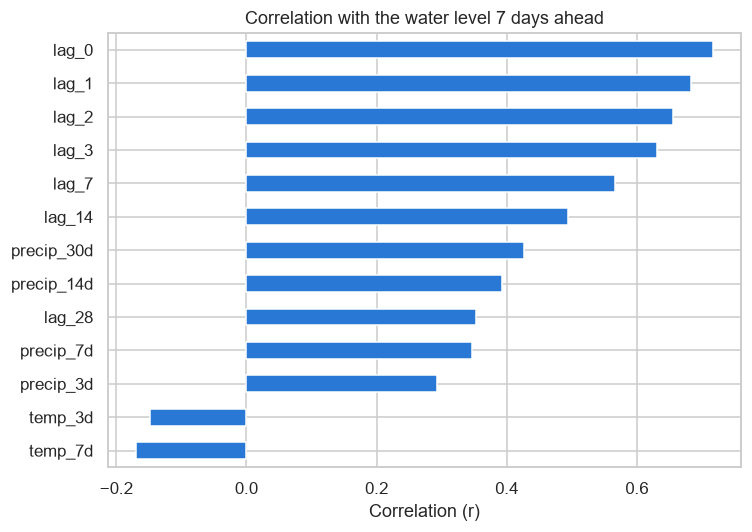

In [9]:
# Correlation between the model features and the 7-day-ahead target
corr_target = features[kp.FEATURES].corrwith(features["target"]).sort_values()

corr_target.plot.barh(figsize=(7, 5), color="#2a78d6")
plt.title("Correlation with the water level 7 days ahead")
plt.xlabel("Correlation (r)")
plt.tight_layout()
plt.show()

## Step 3 + 4: Split, train and evaluate

In [10]:
# Train the model (the pipeline does the split, training and evaluation)
model, report, splits = kp.train(features)

for name, part in splits.items():
    print(f"{name:10s}: {part.index.min().date()} → {part.index.max().date()} n={len(part)}")

train     : 2000-01-30 → 2023-08-25 n=8609
test      : 2023-09-02 → 2026-08-25 n=1089
train_fit : 2000-01-30 → 2021-08-18 n=7872
validation: 2021-08-26 → 2023-08-25 n=730


In [11]:
# Results: validation and test, compared with persistence
report.round(2)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Validation,730,43.47,56.33,0.43,11.93,69.59,45.24,0.04
Test,1089,47.19,63.83,0.68,-0.39,60.51,50.82,0.07


In [12]:
# Error by water condition on the test data
test = splits["test"]
test_predictions = model.predict(test[kp.FEATURES])

high_threshold = splits["train"]["target"].quantile(0.90)

error_summary = hp.regime_table(
    test["target"], test_predictions, test["lag_0"],
    low_cm=LOW_WATER_THRESHOLD, high_cm=high_threshold
)

error_summary.round(2)

,Samples,MAE,RMSE,R²,Bias,Overprediction (%),Persistence MAE,Skill vs persistence
Condition,,,,,,,,
All levels,1089,47.19,63.83,0.68,-0.39,60.51,50.82,0.07
Low water,55,35.86,42.49,-2.68,35.27,94.55,23.58,-0.52
Normal water,882,39.44,48.95,0.47,11.19,65.76,43.81,0.10
High water,152,96.21,120.95,-1.99,-80.44,17.76,101.34,0.05


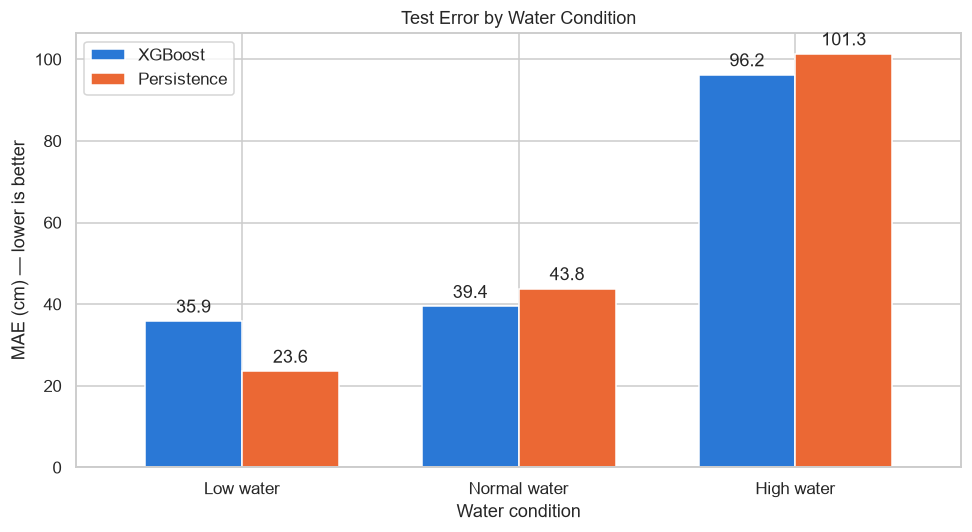

In [13]:
# Bar chart: XGBoost vs persistence per water condition
plot_data = error_summary.loc[["Low water", "Normal water", "High water"],
                              ["MAE", "Persistence MAE"]]
plot_data.columns = ["XGBoost", "Persistence"]

ax = plot_data.plot.bar(figsize=(9, 5), color=["#2a78d6", "#eb6834"], rot=0, width=0.7)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set(title="Test Error by Water Condition", xlabel="Water condition",
       ylabel="MAE (cm) — lower is better")
plt.tight_layout()
plt.show()

In [14]:
# Low-water alarm: will Kaub be below the threshold in 7 days?
pd.DataFrame({
    "XGBoost": hp.alarm_scores(test["target"], test_predictions),
    "Persistence": hp.alarm_scores(test["target"], test["lag_0"]),
}).T.round(3)

,Low-water days,Hits,Missed alarms,False alarms,Recall,Precision
XGBoost,55.0,32.0,23.0,3.0,0.582,0.914
Persistence,55.0,41.0,14.0,7.0,0.745,0.854


## Step 5: Save the model, load it and use it

In [15]:
# Save the model
kp.save_model(model)

print("Saved to", kp.MODEL_PATH)

Saved to C:\Users\Prithvi Hegde\neuefische_course\Rhine-cargo-advisor\models\kaub_xgboost_04.joblib


In [16]:
# Load the saved model again
saved = kp.load_model()

print(saved.keys())
print("Features:", saved["features"])
print("Horizon:", saved["horizon"], "days")

dict_keys(['model', 'features', 'horizon'])
Features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d']
Horizon: 7 days


In [17]:
# Use the saved model: forecast for every day in the data
forecast = kp.predict(saved, daily)

forecast.tail()

,today_level,forecast_date,forecast_level,low_water_alarm
date,,,,
2026-08-28,61.0,2026-09-04,79.862984,False
2026-08-29,70.0,2026-09-05,82.387291,False
2026-08-30,72.0,2026-09-06,79.872345,False
2026-08-31,73.0,2026-09-07,78.124115,False
2026-09-01,68.0,2026-09-08,73.253914,True


In [18]:
# Latest forecast
latest = forecast.iloc[-1]

print(f"Latest day in the data ({forecast.index[-1].date()}): {latest['today_level']:.0f} cm")
print(f"Forecast for {latest['forecast_date'].date()}: {latest['forecast_level']:.0f} cm")
print("Low-water alarm:", "YES" if latest["low_water_alarm"] else "no")

Latest day in the data (2026-09-01): 68 cm
Forecast for 2026-09-08: 73 cm
Low-water alarm: YES


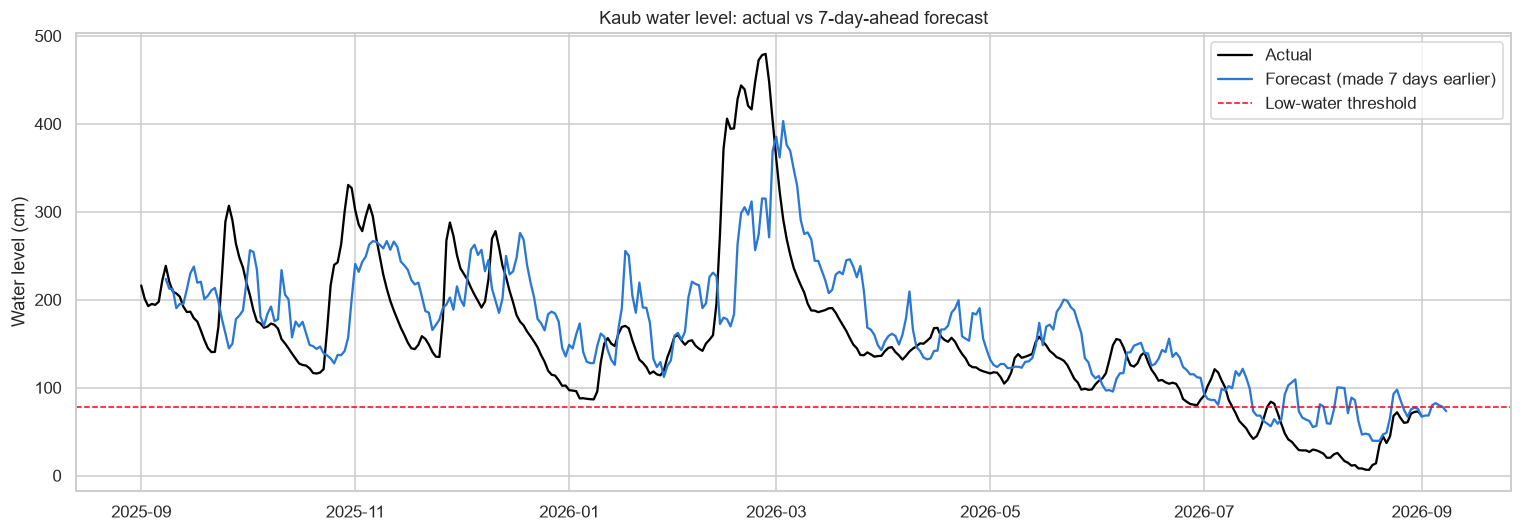

In [19]:
# Plot the last year: actual level vs the 7-day-ahead forecast
last_year = forecast.loc[forecast.index >= forecast.index.max() - pd.Timedelta(days=365)]
actual = daily["water_level_mean"].loc[last_year.index.min():]

plt.figure(figsize=(14, 5))
plt.plot(actual.index, actual, color="black", lw=1.5, label="Actual")
plt.plot(last_year["forecast_date"], last_year["forecast_level"], color="#2a78d6",
         lw=1.5, label="Forecast (made 7 days earlier)")
plt.axhline(LOW_WATER_THRESHOLD, color="red", ls="--", lw=1, label="Low-water threshold")

plt.title("Kaub water level: actual vs 7-day-ahead forecast")
plt.ylabel("Water level (cm)")
plt.legend()
plt.tight_layout()
plt.show()